# RetailHero ABCD · results explorer

Compare all 16 feature combinations for **CausalPFN** and **PTONet**, plus the two formula controls.
This notebook reads the published summaries on CPU. It needs no model checkpoints or GPU.
**Run all cells** to refresh the figures; saved outputs provide an immediate snapshot.

| Block | Added features | Columns |
|---|---|---:|
| Original | Six baseline pre-SMS fields | 6 |
| A | Learned purchase-sequence embedding | +16 |
| B | TabPFN doubly robust uplift score | +1 |
| C | Qwen3 8B LoRA uplift score | +1 |
| D | Four archived, fixed formulas | +4 |

**Read the evidence:** 30% reach is primary; 10% and 20% are secondary; 50% was added after review.
The evaluation cohort was examined previously, so this study remains exploratory.
Only the seven registered 30% comparisons have Holm-adjusted p-values.
An evaluation ranking does not replace the configuration selected on validation.

See [setup and use](README.md), the [protocol](../experiments/retailhero_abcd/PROTOCOL.md),
and the [published report](../reports/retailhero_abcd/REPORT.md).

## 1 · Load the saved results

Choose a Python 3.10+ kernel with the project's `analysis` dependencies. Paths resolve from the
workspace, project, or notebook directory. For another report snapshot, change `PROJECT_ROOT`.
The loader checks configuration coverage, duplicate keys, score identities, and agreement with seed summaries.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.transforms import Bbox

PROJECT_ROOT = None  # Example: Path("/path/to/causal-uplift-engine")
if PROJECT_ROOT is None:
    candidates = [p / suffix for p in (Path.cwd(), *Path.cwd().parents)
                  for suffix in ("", "causal-uplift-engine")]
    PROJECT_ROOT = next((p for p in candidates
                         if (p / "experiments/retailhero_abcd/design.json").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT to the causal-uplift-engine directory.")
PROJECT_ROOT = Path(PROJECT_ROOT).resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Resolve the checkout above before importing its analysis helper.
from experiments.retailhero_abcd.analysis import (  # noqa: E402
    ablation_comparisons,
    compute_stages,
    config_metadata,
    curve_metric_summary,
    load_results,
    registered_comparisons,
)

bundle = load_results(PROJECT_ROOT)
design, result = bundle.design, bundle.results
table, contrasts = bundle.decisions.copy(), bundle.comparisons.copy()
metadata = config_metadata(design)
HOSTS = {"causalpfn": "CausalPFN", "ptonet": "PTONet"}
COLORS = {"causalpfn": "#167d8d", "ptonet": "#8856a7"}
CONFIGS = design["core_configurations"]
REACHES = result["reaches"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 180, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.labelcolor": "#263746",
    "text.color": "#263746", "axes.titlesize": 12,
})
pd.options.display.max_rows = 50
pd.options.display.float_format = "{:,.3f}".format
figures = {}

print(f"Loaded {len(table)} configuration/reach rows from reports/retailhero_abcd")

Loaded 144 configuration/reach rows from reports/retailhero_abcd


In [2]:
# Change these defaults, then rerun the analysis cells below.
REACH = 0.30
INCLUDE_CONTROLS = True
if REACH not in REACHES:
    raise ValueError(f"REACH must be one of {REACHES}")

def reach_label(reach):
    if reach == design["primary_reach"]:
        return f"{reach:.0%} · primary"
    if reach in result.get("post_hoc_reaches", []):
        return f"{reach:.0%} · post hoc"
    return f"{reach:.0%} · secondary"

def at_reach(frame, reach=REACH):
    return frame.loc[np.isclose(frame["reach"], reach)].copy()

def config_names(include_controls):
    return CONFIGS + (design["formula_controls"] if include_controls else [])

selected_configs = config_names(INCLUDE_CONTROLS)
visible_decisions = table.loc[table["config"].isin(selected_configs)]
selected_scores = at_reach(visible_decisions, REACH)

def show_table(frame, formats=None):
    return display(frame.style.format(formats or {}, na_rep="—").hide(axis="index"))

def keep_figure(name, fig):
    figures[name] = fig
    plt.show()

registered = registered_comparisons(bundle)
supported = int(registered["supported_gain"].sum())
counts = result["counts"]
display(Markdown(
    f"**Snapshot:** {counts['train']:,} training · {counts['validation']:,} validation · "
    f"{counts['test']:,} evaluation customers. "
    f"**{supported}/{len(registered)} registered comparisons support a gain** under the saved rule. "
    f"Validation selected **PTONet {result['selection']}**. "
    f"Recorded compute: **{bundle.compute['total_gpu_hours']:.3f} GPU-hours**."
))
show_table(metadata.loc[metadata["config"].isin(selected_configs)],
           {"input_columns": "{:.0f}", "component_count": "{:.0f}"})

**Snapshot:** 140,027 training · 20,004 validation · 40,008 evaluation customers. **0/7 registered comparisons support a gain** under the saved rule. Validation selected **PTONet A**. Recorded compute: **8.991 GPU-hours**.

config,A,B,C,D,input_columns,kind,component_count
Original,False,False,False,False,6,core,0
A,True,False,False,False,22,core,1
B,False,True,False,False,7,core,1
C,False,False,True,False,7,core,1
D,False,False,False,True,10,core,1
AB,True,True,False,False,23,core,2
AC,True,False,True,False,23,core,2
AD,True,False,False,True,26,core,2
BC,False,True,True,False,8,core,2
BD,False,True,False,True,11,core,2


## 2 · Scores across configurations and reach

The score is **1,000 × (purchase rate with SMS − purchase rate without SMS)** within the selected
top-ranked customers. Larger values indicate more incremental buyers per 1,000 SMS.
It is a rate within the selected group: a higher rate at 10% does not itself mean more total buyers than at 30%.
PTONet scores average three separately ranked seed policies.

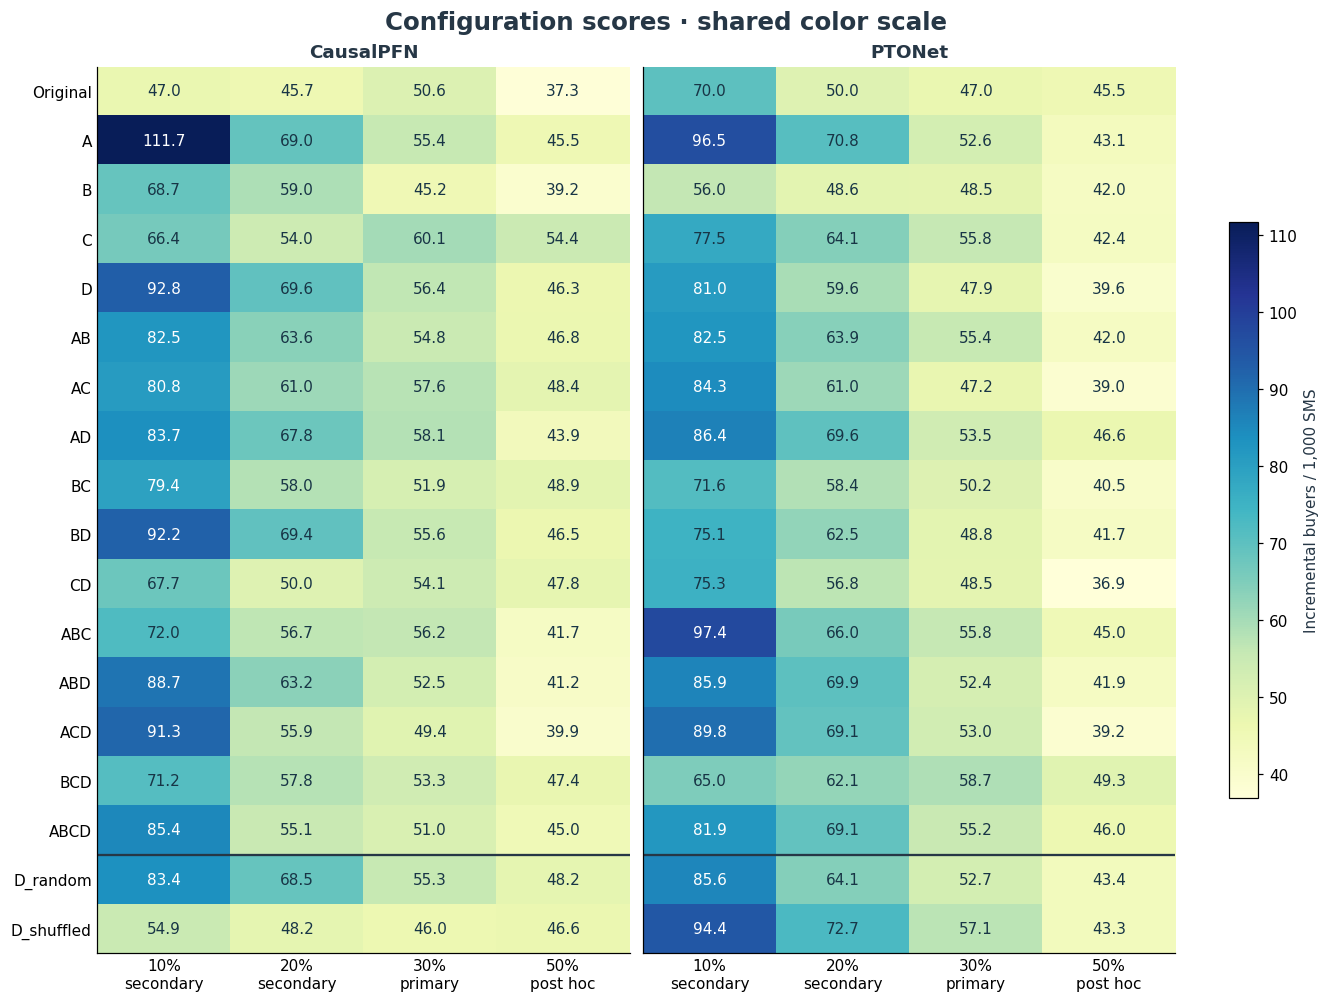

In [3]:
def plot_score_grid(include_controls=True):
    configs = config_names(include_controls)
    subset = table.loc[table["config"].isin(configs)]
    vmin, vmax = subset["challenger_value"].min(), subset["challenger_value"].max()
    fig, axes = plt.subplots(1, 2, figsize=(12, 9), sharey=True, layout="constrained")
    for ax, (host, title) in zip(axes, HOSTS.items(), strict=True):
        grid = subset.loc[subset["host"].eq(host)].pivot(
            index="config", columns="reach", values="challenger_value"
        ).reindex(index=configs, columns=REACHES)
        image = ax.imshow(grid, cmap="YlGnBu", vmin=vmin, vmax=vmax, aspect="auto")
        ax.set(title=title, xticks=range(len(REACHES)),
               xticklabels=[reach_label(r).replace(" · ", "\n") for r in REACHES],
               yticks=range(len(configs)), yticklabels=configs)
        ax.tick_params(axis="both", length=0)
        for i in range(len(configs)):
            for j in range(len(REACHES)):
                value = grid.iloc[i, j]
                ax.text(j, i, f"{value:.1f}", ha="center", va="center",
                        color="white" if (value-vmin)/(vmax-vmin) > .56 else "#183546")
        if include_controls:
            ax.axhline(len(CONFIGS)-.5, color="#263746", linewidth=1.5)
    fig.colorbar(image, ax=axes, shrink=.65, label="Incremental buyers / 1,000 SMS")
    fig.suptitle("Configuration scores · shared color scale", fontsize=16, fontweight="bold")
    return fig

keep_figure("configuration_scores", plot_score_grid(INCLUDE_CONTROLS))

## Which configurations work best at smaller and larger SMS budgets?

Here a budget is the percentage of customers a policy can target. Read across a row to see how a
configuration's advantage changes as reach expands. Each number is its score minus **Original for
the same host at the same reach**, in incremental buyers per 1,000 SMS. Read down a column to compare
configurations competing for the same budget. The outlined cell is the highest observed core score.
The bottom two rows, when shown, are formula controls.

These are descriptive comparisons on the reused evaluation cohort. The 50% budget was added after review.

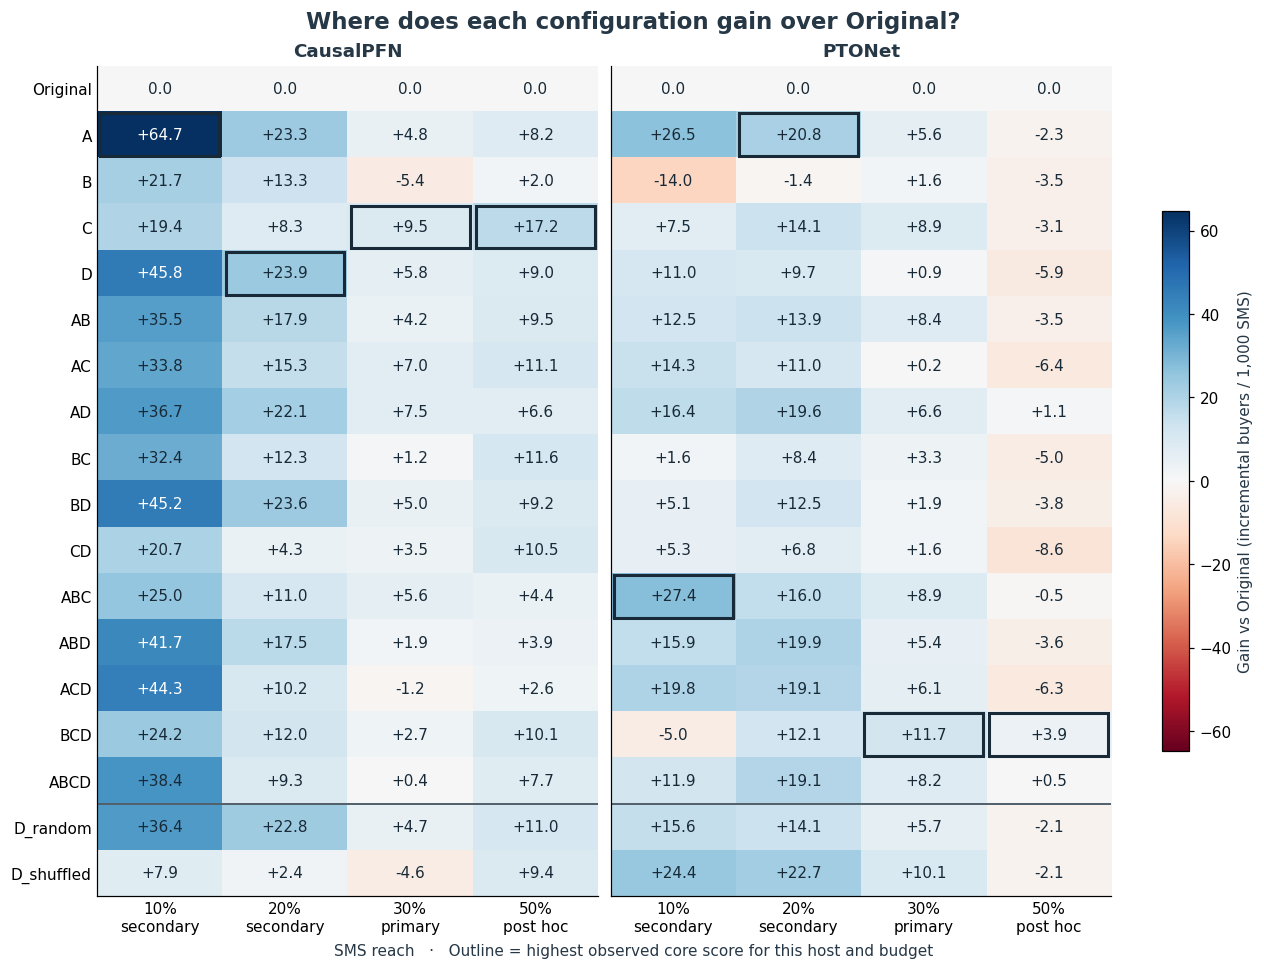

In [4]:
from matplotlib.patches import Rectangle

budgets = sorted(REACHES)
gain_limit = max(1., visible_decisions["gain"].abs().max())
fig, axes = plt.subplots(1, 2, figsize=(11.4, 8.7), sharey=True, layout="constrained")
for ax, (host, title) in zip(axes, HOSTS.items(), strict=True):
    gains = (visible_decisions.loc[visible_decisions["host"].eq(host)]
             .pivot(index="config", columns="reach", values="gain")
             .reindex(index=selected_configs, columns=budgets))
    image = ax.imshow(gains, cmap="RdBu", vmin=-gain_limit, vmax=gain_limit, aspect="auto")
    for j, reach in enumerate(budgets):
        best_core = gains.loc[CONFIGS, reach].max()
        for i, config in enumerate(selected_configs):
            value = gains.loc[config, reach]
            ax.text(j, i, f"{value:+.1f}" if value else "0.0", ha="center", va="center",
                    color="white" if abs(value) > .62*gain_limit else "#182a37")
            if config in CONFIGS and value == best_core:
                ax.add_patch(Rectangle((j-.475, i-.465), .95, .93, fill=False,
                                       edgecolor="#182a37", linewidth=2))
    ax.set(title=title, yticks=range(len(selected_configs)), yticklabels=selected_configs,
           xticks=range(len(budgets)), xticklabels=[reach_label(r).replace(" · ", "\n") for r in budgets])
    ax.tick_params(length=0)
    if INCLUDE_CONTROLS:
        ax.axhline(len(CONFIGS)-.5, color="#53616c", linewidth=1.3)
fig.colorbar(image, ax=axes, shrink=.65, label="Gain vs Original (incremental buyers / 1,000 SMS)")
fig.suptitle("Where does each configuration gain over Original?", fontsize=15, fontweight="bold")
fig.supxlabel("SMS reach   ·   Outline = highest observed core score for this host and budget", fontsize=10)
keep_figure("budget_performance", fig)

### Follow individual methods across the four budgets

Change `BUDGET_HOST` and `BUDGET_CONFIGS` in the next cell to compare core configurations.
The default example follows PTONet ABC and BCD because their observed order reverses as reach expands.
On the left, whiskers show the saved pointwise paired 95% intervals against Original within each budget.
On the right, rank 1 is the highest evaluation score among the 16 core configurations for that host.
A change in rank can occur even when both methods' absolute scores decline. The intervals quantify
within-budget gains. Testing whether the gap between two methods changes with reach requires a separate contrast.

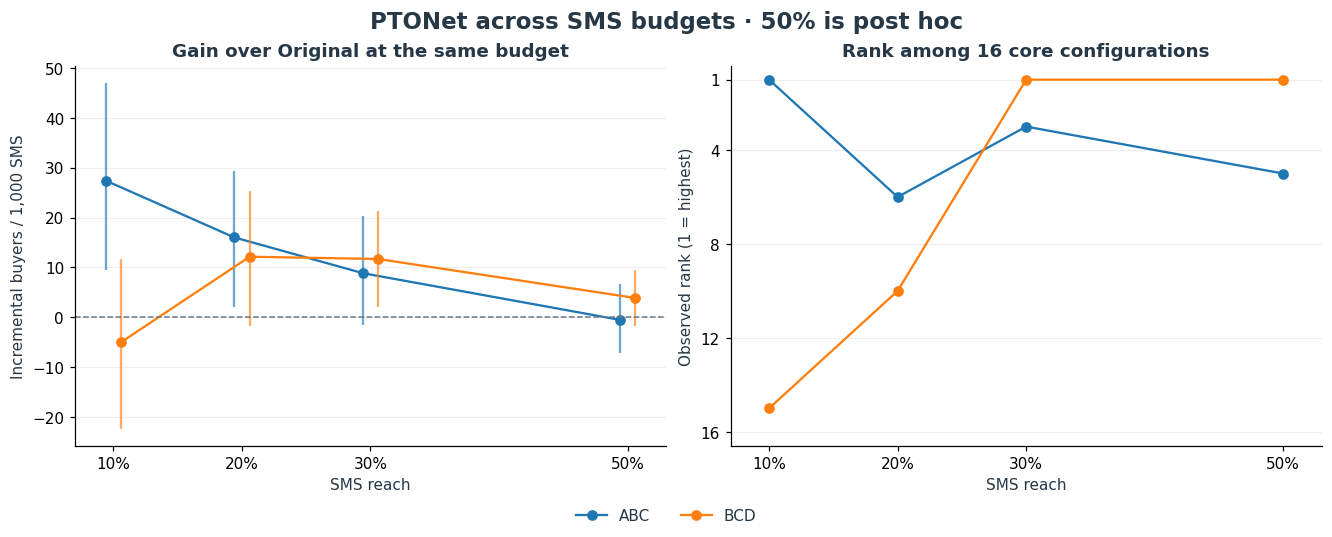

In [5]:
BUDGET_HOST = "ptonet"              # "causalpfn" or "ptonet"
BUDGET_CONFIGS = ["ABC", "BCD"]     # Choose any distinct core configurations, including "Original".

if BUDGET_HOST not in HOSTS or not BUDGET_CONFIGS or not set(BUDGET_CONFIGS) <= set(CONFIGS):
    raise ValueError(f"Choose a host from {list(HOSTS)} and configurations from {CONFIGS}.")
if len(BUDGET_CONFIGS) != len(set(BUDGET_CONFIGS)):
    raise ValueError("Choose each configuration once.")
core = table.loc[table["host"].eq(BUDGET_HOST) & table["config"].isin(CONFIGS)].copy()
core["rank"] = core.groupby("reach")["challenger_value"].rank(method="min", ascending=False)
fig, (gain_ax, rank_ax) = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
positions = np.array(budgets) * 100
colors = plt.get_cmap("tab10" if len(BUDGET_CONFIGS) <= 10 else "tab20")
for i, config in enumerate(BUDGET_CONFIGS):
    series = core.loc[core["config"].eq(config)].set_index("reach").loc[budgets]
    color = colors(i)
    # Give each interval a little horizontal space at each measured budget.
    offset = 0 if len(BUDGET_CONFIGS) == 1 else 1.2 * (i/(len(BUDGET_CONFIGS)-1) - .5)
    gain_ax.vlines(positions+offset, series["low_95"], series["high_95"], color=color, alpha=.65)
    gain_ax.plot(positions+offset, series["gain"], "o-", color=color, label=config)
    rank_ax.plot(positions, series["rank"], "o-", color=color, label=config)
gain_ax.axhline(0, color="#677786", lw=1, ls="--")
gain_ax.set(title="Gain over Original at the same budget", ylabel="Incremental buyers / 1,000 SMS")
rank_ax.set(title=f"Rank among {len(CONFIGS)} core configurations",
            ylabel="Observed rank (1 = highest)", ylim=(len(CONFIGS)+.6, .4),
            yticks=[1, 4, 8, 12, len(CONFIGS)])
for ax in (gain_ax, rank_ax):
    ax.set(xticks=positions, xticklabels=[f"{r:.0%}" for r in budgets], xlabel="SMS reach", xlim=(7, 53))
    ax.grid(axis="y", alpha=.2)
fig.legend(*rank_ax.get_legend_handles_labels(), loc="outside lower center",
           ncol=min(len(BUDGET_CONFIGS), 8), frameon=False)
fig.suptitle(f"{HOSTS[BUDGET_HOST]} across SMS budgets · 50% is post hoc", weight="bold", fontsize=15)
keep_figure("budget_method_profiles", fig)

## 3 · Gains against the same host's Original

Dots show score differences; whiskers are the saved **paired customer-bootstrap 95% intervals for those differences**.
They are not intervals around the absolute scores. Most grid comparisons are exploratory and pointwise.
The displayed configuration order follows the design, avoiding a ranking chosen from evaluation outcomes.

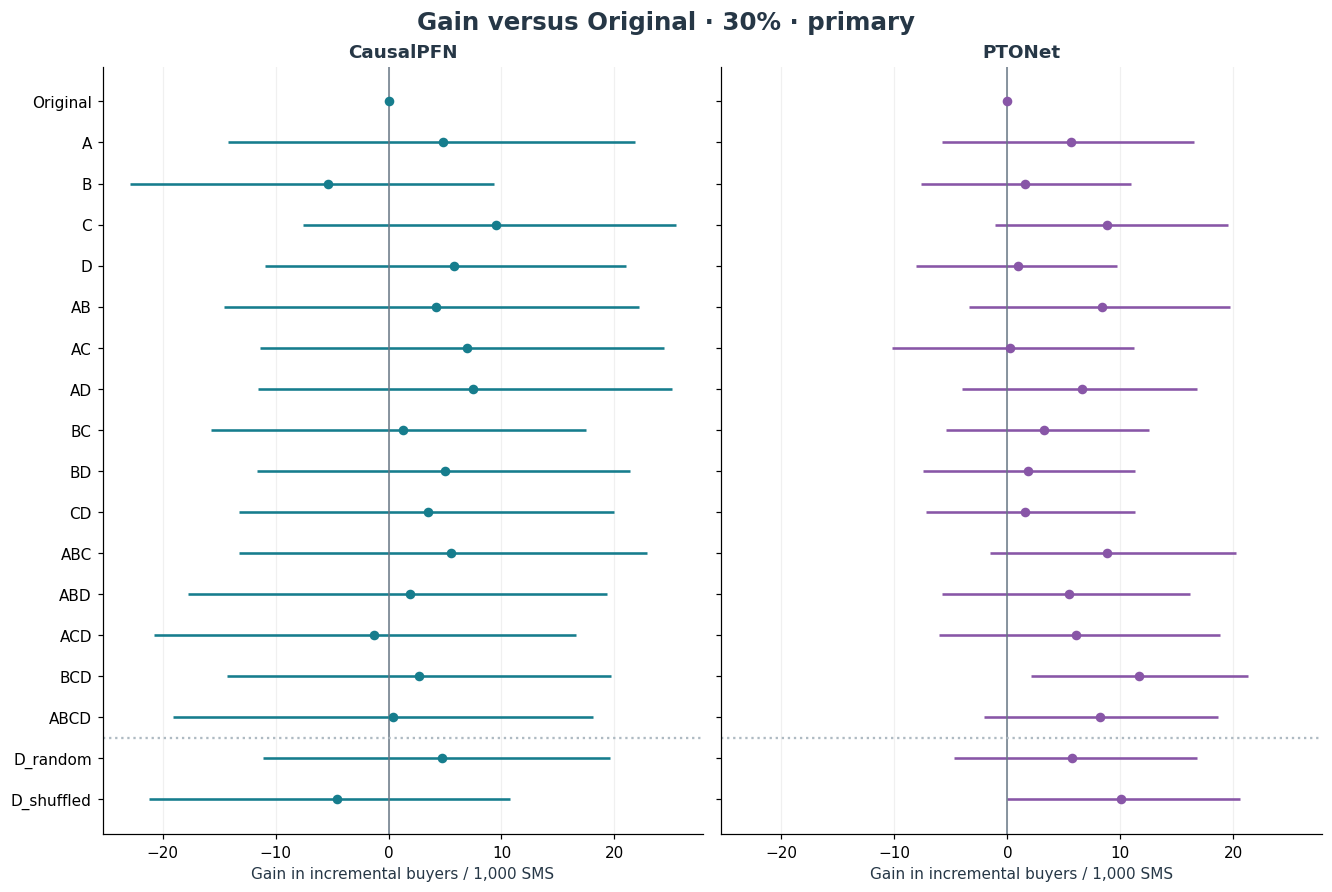

host,config,input_columns,challenger_value,gain,low_95,high_95,seed_sd,validation_mean
causalpfn,Original,6,50.61,0.00,0.00,0.00,—,53.42
causalpfn,A,22,55.41,4.80,-14.22,21.78,—,66.77
causalpfn,B,7,45.25,-5.36,-22.90,9.30,—,51.31
causalpfn,C,7,60.10,9.49,-7.55,25.42,—,60.19
causalpfn,D,10,56.39,5.79,-10.89,21.05,—,80.68
causalpfn,AB,23,54.83,4.22,-14.57,22.21,—,61.45
causalpfn,AC,23,57.59,6.99,-11.40,24.36,—,59.25
causalpfn,AD,26,58.06,7.46,-11.54,25.11,—,64.95
causalpfn,BC,8,51.85,1.24,-15.68,17.51,—,64.82
causalpfn,BD,11,55.58,4.97,-11.60,21.39,—,69.51


In [6]:
def plot_gains(reach=REACH, include_controls=True):
    configs = config_names(include_controls)
    selected = at_reach(table, reach)
    fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True, sharex=True,
                             layout="constrained")
    for ax, (host, title) in zip(axes, HOSTS.items(), strict=True):
        rows = selected.loc[selected["host"].eq(host)].set_index("config").reindex(configs)
        y = np.arange(len(rows))
        ax.hlines(y, rows["low_95"], rows["high_95"], color=COLORS[host], linewidth=1.7)
        ax.scatter(rows["gain"], y, color=COLORS[host], s=28, zorder=3)
        ax.axvline(0, color="#677786", linewidth=1)
        ax.set(title=title, yticks=y, yticklabels=configs,
               xlabel="Gain in incremental buyers / 1,000 SMS")
        ax.grid(axis="x", alpha=.18)
        if include_controls:
            ax.axhline(len(CONFIGS)-.5, color="#aebac2", linestyle=":")
    axes[0].invert_yaxis()
    fig.suptitle(f"Gain versus Original · {reach_label(reach)}", fontsize=16, fontweight="bold")
    return fig

keep_figure("gains_vs_original", plot_gains(REACH, INCLUDE_CONTROLS))
score_columns = ["host", "config", "input_columns", "challenger_value", "gain", "low_95", "high_95",
                 "seed_sd", "validation_mean"]
show_table(selected_scores[score_columns], {c: "{:.2f}" for c in score_columns[3:]})

## 4 · The seven registered decisions

These comparisons stay fixed at **30% reach**, independently of the exploration controls.
A supported gain requires a positive lower interval bound **and** Holm p < .05 across all seven tests.
Intervals use 5,000 common treatment-stratified customer bootstrap samples, with re-ranking within each sample.
The cross-host row uses the PTONet configuration selected on validation.

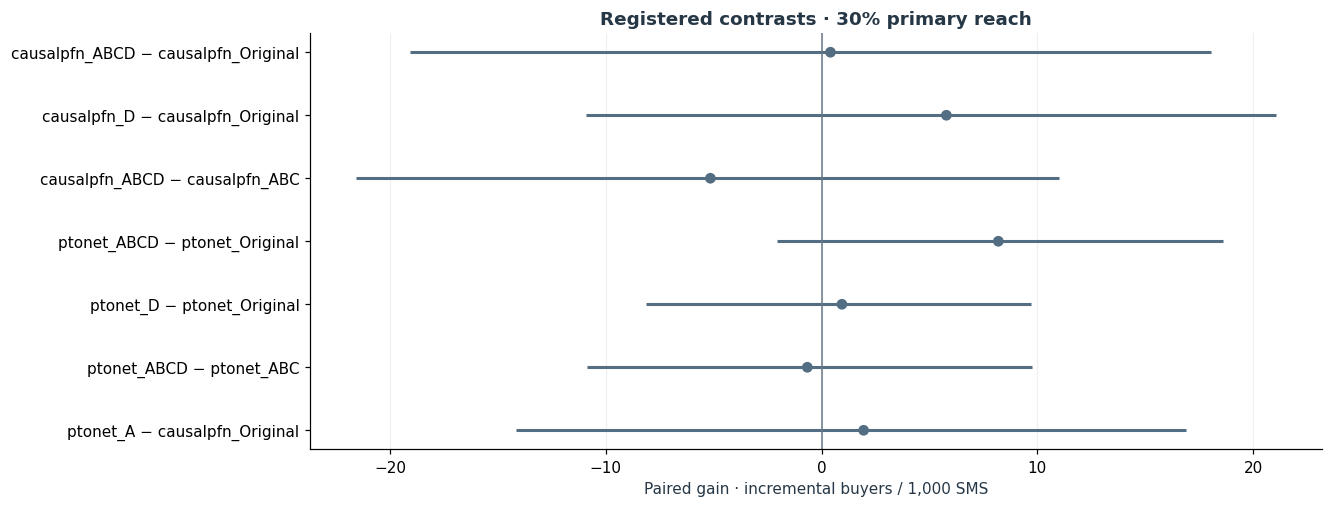

challenger,reference,gain,low_95,high_95,p_holm_7,supported_gain
causalpfn_ABCD,causalpfn_Original,+0.41,-19.08,+18.07,1.0000,False
causalpfn_D,causalpfn_Original,+5.79,-10.89,+21.05,1.0000,False
causalpfn_ABCD,causalpfn_ABC,-5.15,-21.57,+11.01,1.0000,False
ptonet_ABCD,ptonet_Original,+8.19,-2.06,+18.62,0.8594,False
ptonet_D,ptonet_Original,+0.95,-8.12,+9.71,1.0000,False
ptonet_ABCD,ptonet_ABC,-0.66,-10.85,+9.76,1.0000,False
ptonet_A,causalpfn_Original,+1.95,-14.18,+16.90,1.0000,False


In [7]:
fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
labels = registered["challenger"] + " − " + registered["reference"]
y = np.arange(len(registered))
ax.hlines(y, registered["low_95"], registered["high_95"], color="#536d83", linewidth=2)
ax.scatter(registered["gain"], y, c=np.where(registered["supported_gain"], "#21805e", "#536d83"), zorder=3)
ax.axvline(0, color="#677786", linewidth=1)
ax.set(yticks=y, yticklabels=labels, xlabel="Paired gain · incremental buyers / 1,000 SMS",
       title="Registered contrasts · 30% primary reach")
ax.invert_yaxis()
ax.grid(axis="x", alpha=.18)
keep_figure("registered_contrasts", fig)
show_table(registered[["challenger", "reference", "gain", "low_95", "high_95", "p_holm_7", "supported_gain"]],
           {"gain": "{:+.2f}", "low_95": "{:+.2f}", "high_95": "{:+.2f}", "p_holm_7": "{:.4f}"})

## 5 · Where each component helps

**Left:** adding one block to the other three, e.g. ABCD − BCD measures A in that background.
**Right:** the saved factorial effect averages the eight matched add/remove pairs for each block.
These are different questions. The blocks include their full inputs and preprocessing; these comparisons
do not isolate the value of a particular architecture. A/B/C ablations and all factorial averages are exploratory.

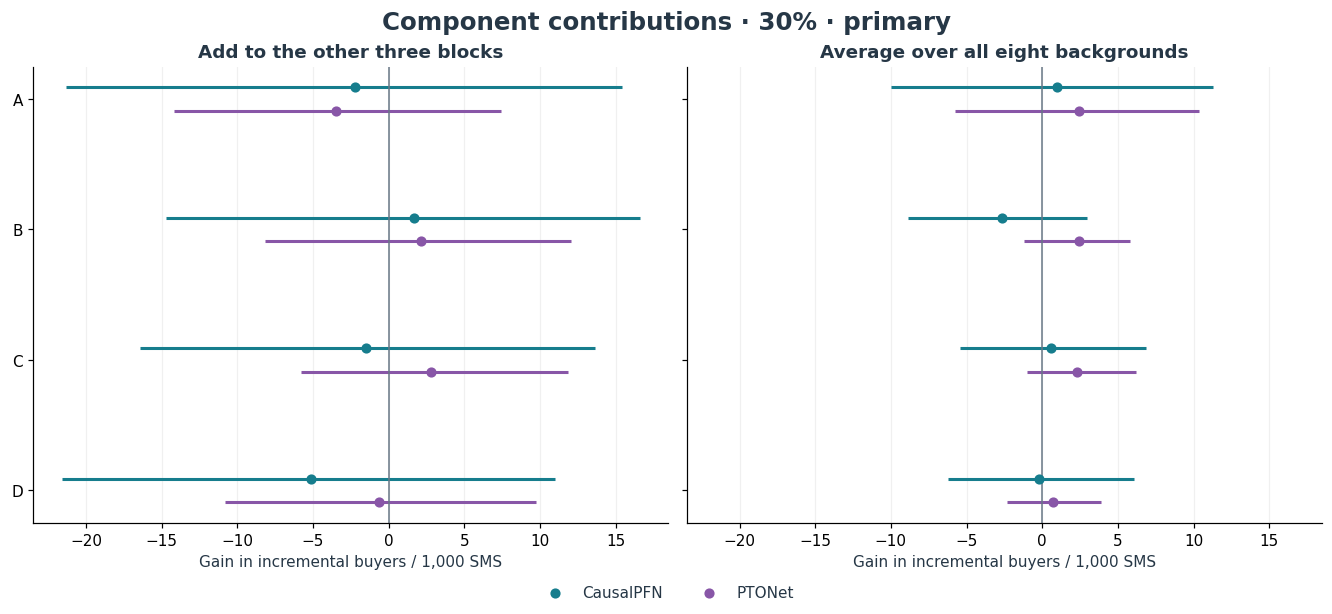

host,component,reference,gain,low_95,high_95,family
causalpfn,A,causalpfn_BCD,-2.25,-21.30,+15.42,exploratory_ablation
causalpfn,B,causalpfn_ACD,+1.66,-14.73,+16.57,exploratory_ablation
causalpfn,C,causalpfn_ABD,-1.52,-16.41,+13.64,exploratory_ablation
causalpfn,D,causalpfn_ABC,-5.15,-21.57,+11.01,registered
ptonet,A,ptonet_BCD,-3.49,-14.18,+7.40,exploratory_ablation
ptonet,B,ptonet_ACD,+2.12,-8.15,+12.02,exploratory_ablation
ptonet,C,ptonet_ABD,+2.78,-5.81,+11.83,exploratory_ablation
ptonet,D,ptonet_ABC,-0.66,-10.85,+9.76,registered


In [8]:
ablation = ablation_comparisons(bundle, REACH)
effects = at_reach(bundle.effects)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, sharex=True, layout="constrained")
for ax, frame, title in zip(axes, [ablation, effects],
                           ["Add to the other three blocks", "Average over all eight backgrounds"],
                           strict=True):
    for h, (host, label) in enumerate(HOSTS.items()):
        rows = frame.loc[frame["host"].eq(host)].set_index("component").reindex(list("ABCD"))
        y = np.arange(4) + (h-.5)*.18
        ax.hlines(y, rows["low_95"], rows["high_95"], color=COLORS[host], linewidth=2)
        ax.scatter(rows["gain"], y, color=COLORS[host], label=label, s=32, zorder=3)
    ax.axvline(0, color="#677786", linewidth=1)
    ax.set(title=title, yticks=range(4), yticklabels=list("ABCD"),
           xlabel="Gain in incremental buyers / 1,000 SMS")
    ax.grid(axis="x", alpha=.18)
axes[0].invert_yaxis()
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(f"Component contributions · {reach_label(REACH)}", fontsize=16, fontweight="bold")
keep_figure("component_effects", fig)
show_table(ablation[["host", "component", "reference", "gain", "low_95", "high_95", "family"]],
           {"gain": "{:+.2f}", "low_95": "{:+.2f}", "high_95": "{:+.2f}"})

## 6 · Reach, formula controls, and standalone scores

Lines connect only the measured budgets. Formula controls are outside the 16-configuration factorial grid.
The random-formula control includes a sign-reversed archived subtraction, which retains that feature's information.
Standalone B/C rows are diagnostics; they were not selected as deployment winners.

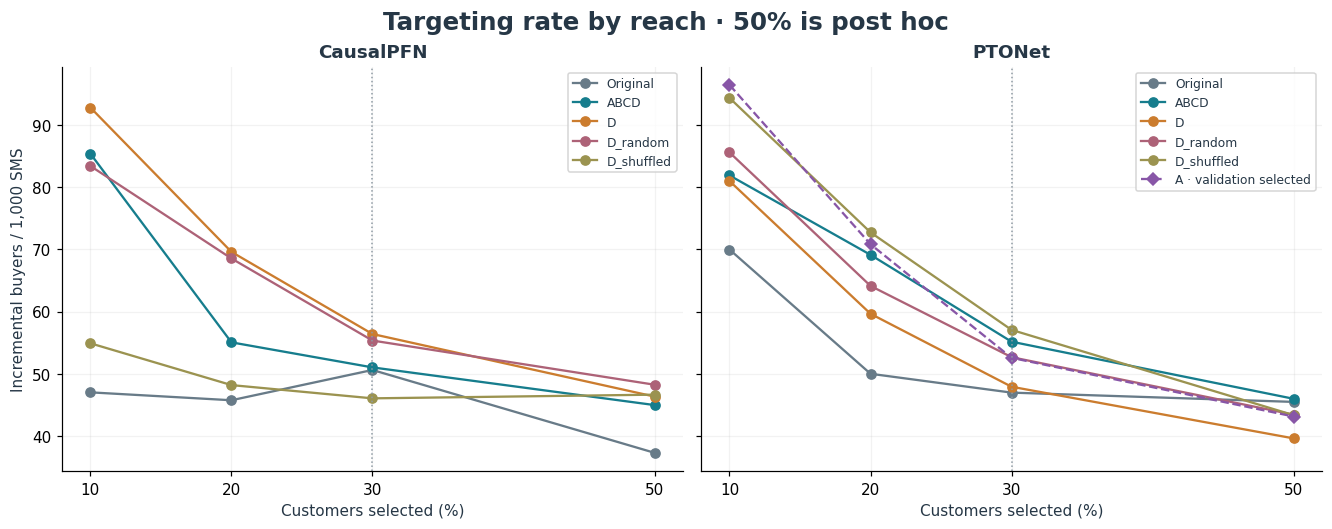

reach,standalone_B,standalone_C
10%,96.63,50.52
20%,76.26,37.86
30%,63.67,34.14
50%,52.13,36.74


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), sharey=True, layout="constrained")
line_configs = [c for c in ["Original", "ABCD", "D", "D_random", "D_shuffled"] if c in selected_configs]
line_colors = ["#687b88", "#167d8d", "#cb7c2e", "#ad6277", "#9b9350"]
for ax, (host, title) in zip(axes, HOSTS.items(), strict=True):
    host_rows = visible_decisions.loc[visible_decisions["host"].eq(host)]
    for config, color in zip(line_configs, line_colors, strict=False):
        rows = host_rows.loc[host_rows["config"].eq(config)].sort_values("reach")
        ax.plot(100*rows["reach"], rows["challenger_value"], "o-", label=config, color=color)
    if host == "ptonet" and result["selection"] not in line_configs:
        rows = host_rows.loc[host_rows["config"].eq(result["selection"])].sort_values("reach")
        ax.plot(100*rows["reach"], rows["challenger_value"], "D--", color=COLORS[host],
                label=f"{result['selection']} · validation selected")
    ax.axvline(30, color="#8f9ba4", linestyle=":", linewidth=1)
    ax.set(title=title, xlabel="Customers selected (%)", xticks=[100*r for r in REACHES])
    ax.grid(alpha=.16)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Incremental buyers / 1,000 SMS")
fig.suptitle("Targeting rate by reach · 50% is post hoc", fontsize=16, fontweight="bold")
keep_figure("reach_and_controls", fig)
diagnostics = pd.DataFrame(result["diagnostic_values"], index=REACHES).rename_axis("reach").reset_index()
show_table(diagnostics, {"reach": "{:.0%}", **{k: "{:.2f}" for k in result["diagnostic_values"]}})

## 7 · Training seeds and full-curve metrics

The dots below are the three PTONet seed policies, not confidence intervals. Seed variability and customer-bootstrap
uncertainty describe different sources of variation. CausalPFN has only one seed, so its missing seed SD is unknown variability.
Qini/AUUC summarize the full ranking and repeat at every reach in the source CSV; they are deduplicated before averaging.

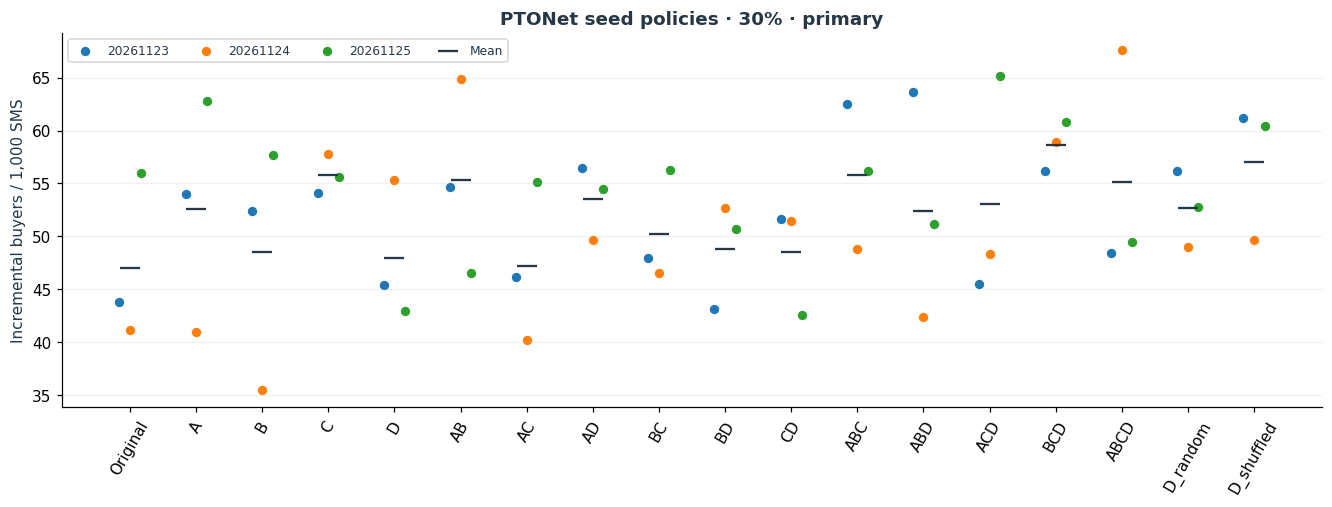

host,config,policies,qini_mean,qini_seed_sd,auuc_mean,auuc_seed_sd
causalpfn,A,1,0.00989,—,0.01539,—
causalpfn,AB,1,0.01380,—,0.02121,—
causalpfn,ABC,1,0.00891,—,0.01390,—
causalpfn,ABCD,1,0.00980,—,0.01535,—
causalpfn,ABD,1,0.00800,—,0.01253,—
causalpfn,AC,1,0.01043,—,0.01615,—
causalpfn,ACD,1,0.00830,—,0.01280,—
causalpfn,AD,1,0.00853,—,0.01319,—
causalpfn,B,1,0.00661,—,0.01043,—
causalpfn,BC,1,0.00921,—,0.01434,—


In [10]:
seed_rows = at_reach(bundle.seeds)
seed_rows = seed_rows.loc[seed_rows["policy"].str.startswith("ptonet_")].copy()
seed_rows["config"] = seed_rows["policy"].str.removeprefix("ptonet_")
seed_order = sorted(seed_rows["seed"].unique())
configs = selected_configs
fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
for i, seed in enumerate(seed_order):
    values = seed_rows.loc[seed_rows["seed"].eq(seed)].set_index("config").reindex(configs)["value"]
    ax.scatter(np.arange(len(configs))+(i-1)*.16, values, label=str(int(seed)), s=26)
means = selected_scores.loc[selected_scores["host"].eq("ptonet")].set_index("config").reindex(configs)
ax.scatter(range(len(configs)), means["challenger_value"], marker="_", s=160, color="#263746", label="Mean")
ax.set(xticks=range(len(configs)), xticklabels=configs, ylabel="Incremental buyers / 1,000 SMS",
       title=f"PTONet seed policies · {reach_label(REACH)}")
ax.tick_params(axis="x", rotation=60)
ax.legend(ncol=4, fontsize=8)
ax.grid(axis="y", alpha=.18)
keep_figure("ptonet_seed_variability", fig)

curve_metrics = curve_metric_summary(bundle)
curve_metrics = curve_metrics.loc[
    curve_metrics["host"].eq("standalone") | curve_metrics["config"].isin(selected_configs)
]
show_table(curve_metrics, {c: "{:.5f}" for c in curve_metrics if c.startswith(("qini", "auuc"))})

## 8 · Validation and evaluation by configuration

Each pair shows all 16 configurations for each method at one evaluation reach. The horizontal axis uses
the recorded **30% validation score** throughout. The two panels and overlay share the same vertical scale
within each reach. The scale adjusts between reaches so nearby configurations stay readable.
Teal circles denote CausalPFN and purple squares denote PTONet.

In [11]:
core_scores = table.loc[table["config"].isin(CONFIGS)]
host_markers = {"causalpfn": "o", "ptonet": "s"}

def score_limits(values):
    padding = max(float(values.max() - values.min()) * .10, 1.)
    return values.min() - padding, values.max() + padding

x_limits = score_limits(core_scores["validation_mean"])
x_label = "Validation at 30% reach (incremental buyers / 1,000 SMS)"

def plot_host(ax, host, rows, y_limits):
    ax.scatter(rows["validation_mean"], rows["challenger_value"], s=35, marker=host_markers[host],
               color=COLORS[host], label=HOSTS[host], zorder=3)
    ax.set(xlim=x_limits, ylim=y_limits, xlabel=x_label)
    ax.grid(alpha=.16)

def label_scores(ax, rows):
    # Try nearby positions in display coordinates while keeping the data points fixed.
    renderer = ax.figure.canvas.get_renderer()
    px = renderer.points_to_pixels(1)
    coords = ax.transData.transform(rows[["validation_mean", "challenger_value"]].to_numpy())
    r = 4.1 * px
    occupied = [Bbox.from_extents(x-r, y-r, x+r, y+r) for x, y in coords]
    directions = [(1, 0), (-1, 0), (1, 1), (-1, 1), (1, -1), (-1, -1), (0, 1), (0, -1)]
    for i, row in enumerate(rows.itertuples()):
        point = (row.validation_mean, row.challenger_value)
        label = ax.annotate(row.config, point, xytext=(0, 0), textcoords="offset points",
                            color=COLORS[row.host], fontsize=8.5, zorder=5)
        for gap in (6, 10, 15, 22, 32, 45, 65):
            for dx, dy in directions:
                label.set_position((dx*gap, dy*gap))
                label.set_ha({-1: "right", 0: "center", 1: "left"}[dx])
                label.set_va({-1: "top", 0: "center", 1: "bottom"}[dy])
                bounds = label.get_window_extent(renderer).padded(1.5 * px)
                if (ax.bbox.contains(*bounds.min) and ax.bbox.contains(*bounds.max)
                    and not any(bounds.overlaps(other) for other in occupied)):
                    break
            else:
                continue
            break
        occupied.append(bounds)
        # A fine leader connects an offset label to its point in a dense cluster.
        closest = np.clip(coords[i], bounds.min, bounds.max)
        if (dx and dy) or np.linalg.norm(closest - coords[i]) > 7 * px:
            end = ax.transData.inverted().transform(closest)
            ax.plot([point[0], end[0]], [point[1], end[1]], color=COLORS[row.host],
                    linewidth=.65, alpha=.65, zorder=2, scalex=False, scaley=False)

def scatter_pair(reach):
    rows = at_reach(core_scores, reach)
    y_limits = score_limits(rows["challenger_value"])
    y_label = f"Evaluation at {reach:.0%} reach (incremental buyers / 1,000 SMS)"
    panels, axes = plt.subplots(1, 2, figsize=(13, 5.9), sharex=True, sharey=True, layout="constrained")
    overlay, combined = plt.subplots(figsize=(12, 6.4), layout="constrained")
    for ax, (host, title) in zip(axes, HOSTS.items(), strict=True):
        host_rows = rows.loc[rows["host"].eq(host)]
        plot_host(ax, host, host_rows, y_limits)
        plot_host(combined, host, host_rows, y_limits)
        ax.set_title(title)
    axes[0].set_ylabel(y_label)
    combined.set_ylabel(y_label)
    panels.suptitle(f"Validation and evaluation by configuration · {reach_label(reach)}",
                    fontsize=16, fontweight="bold")
    combined.set_title(f"CausalPFN and PTONet · {reach_label(reach)} evaluation reach")
    overlay.legend(*combined.get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
    for fig in (panels, overlay):
        fig.canvas.draw()
        fig.set_layout_engine("none")
    for ax, host in zip(axes, HOSTS, strict=True):
        label_scores(ax, rows.loc[rows["host"].eq(host)])
    label_scores(combined, rows)
    return panels, overlay

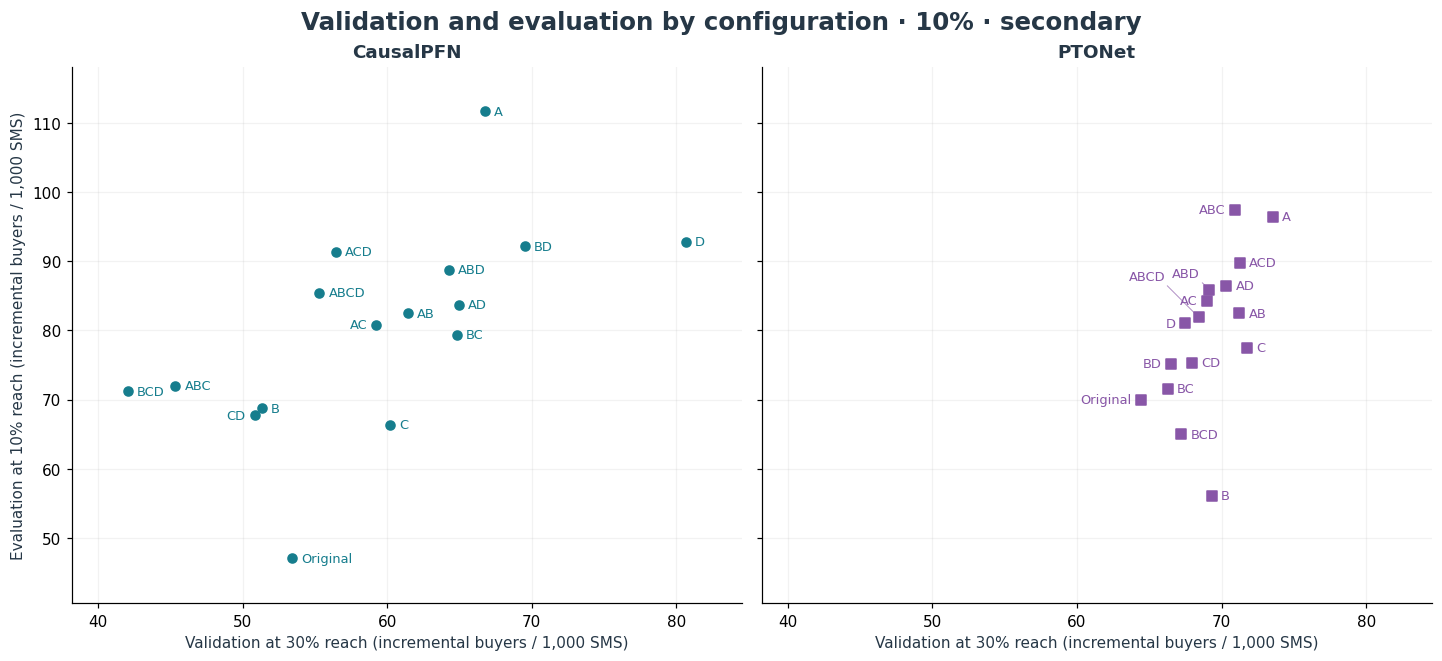

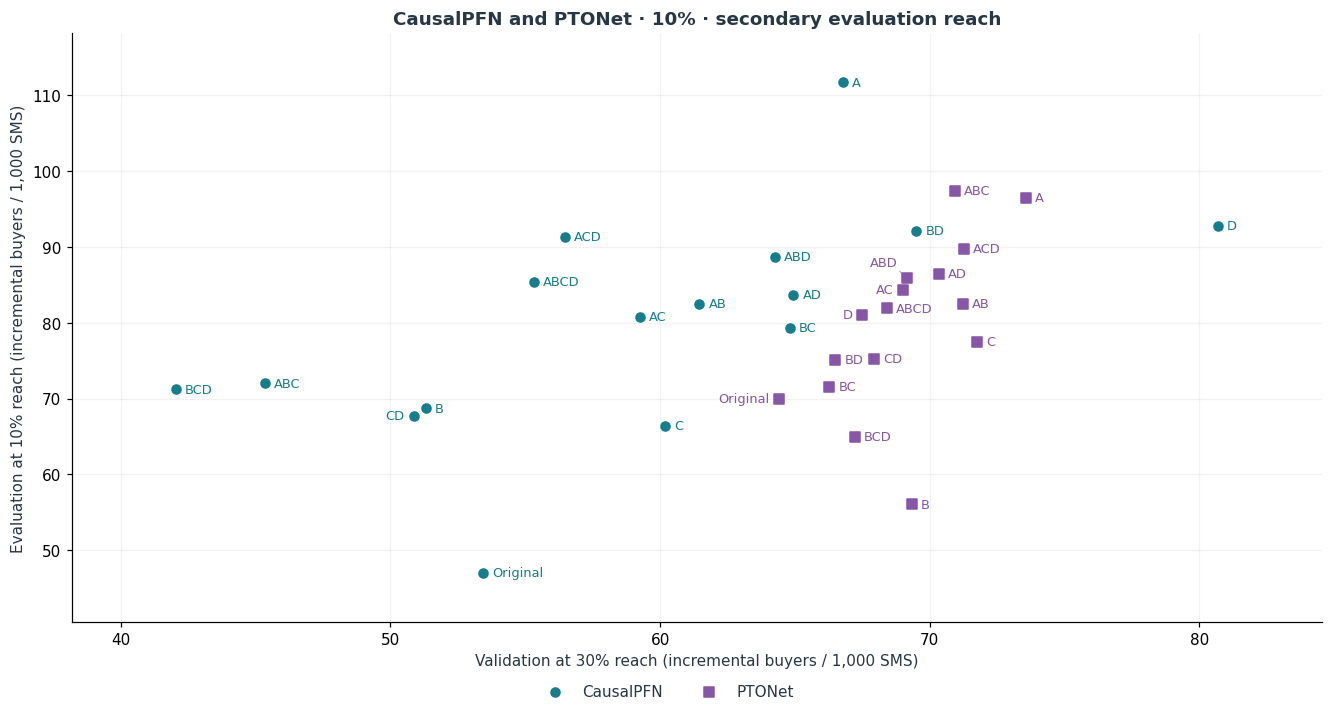

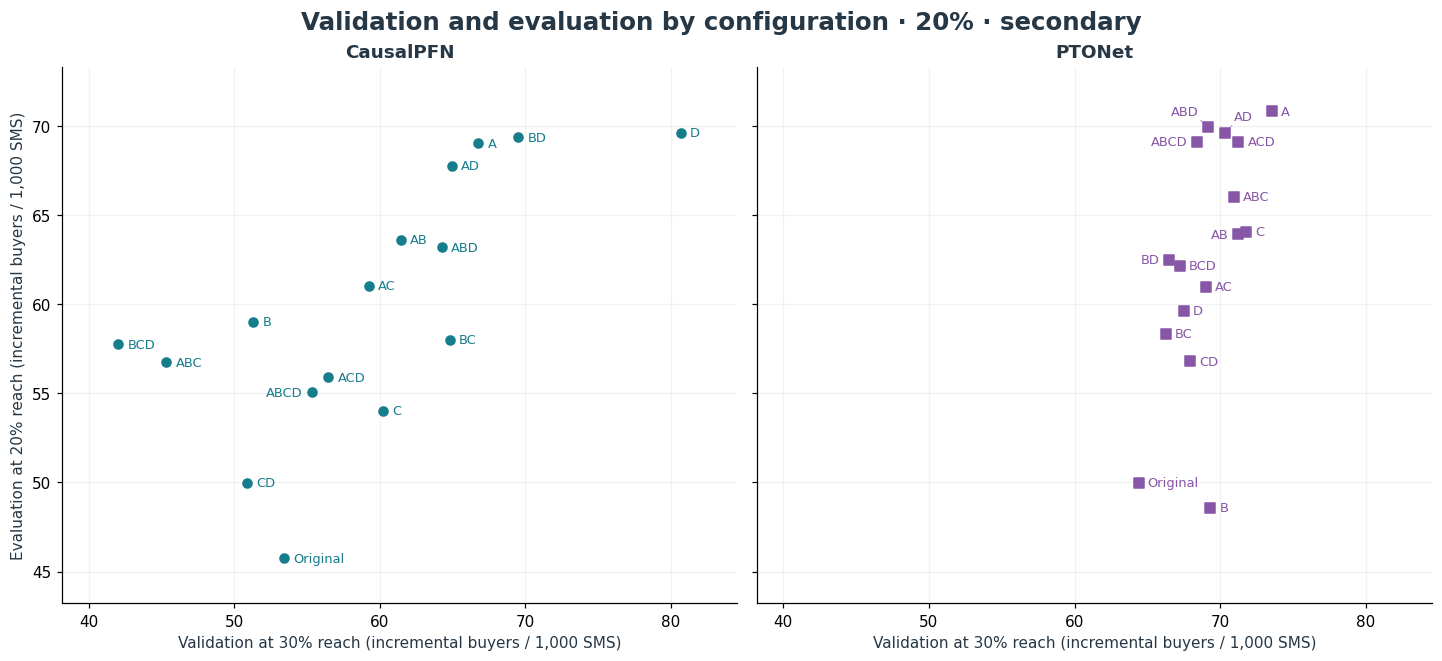

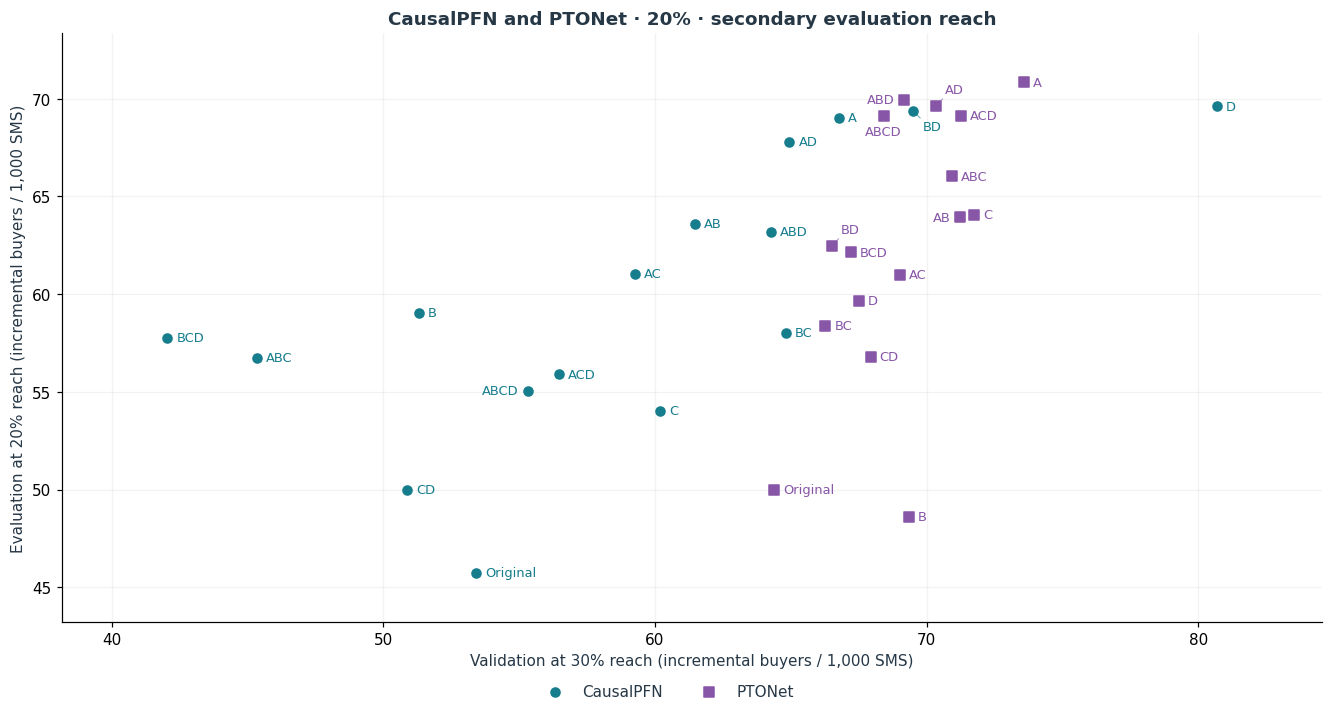

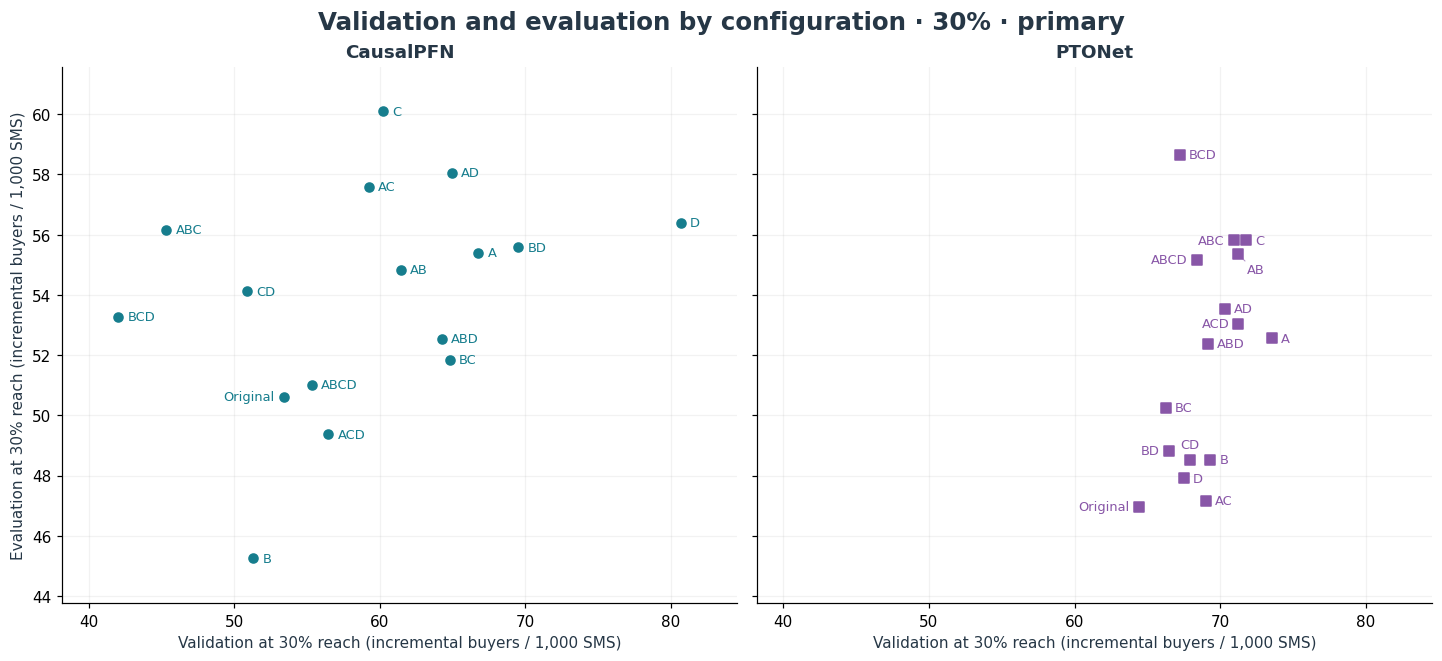

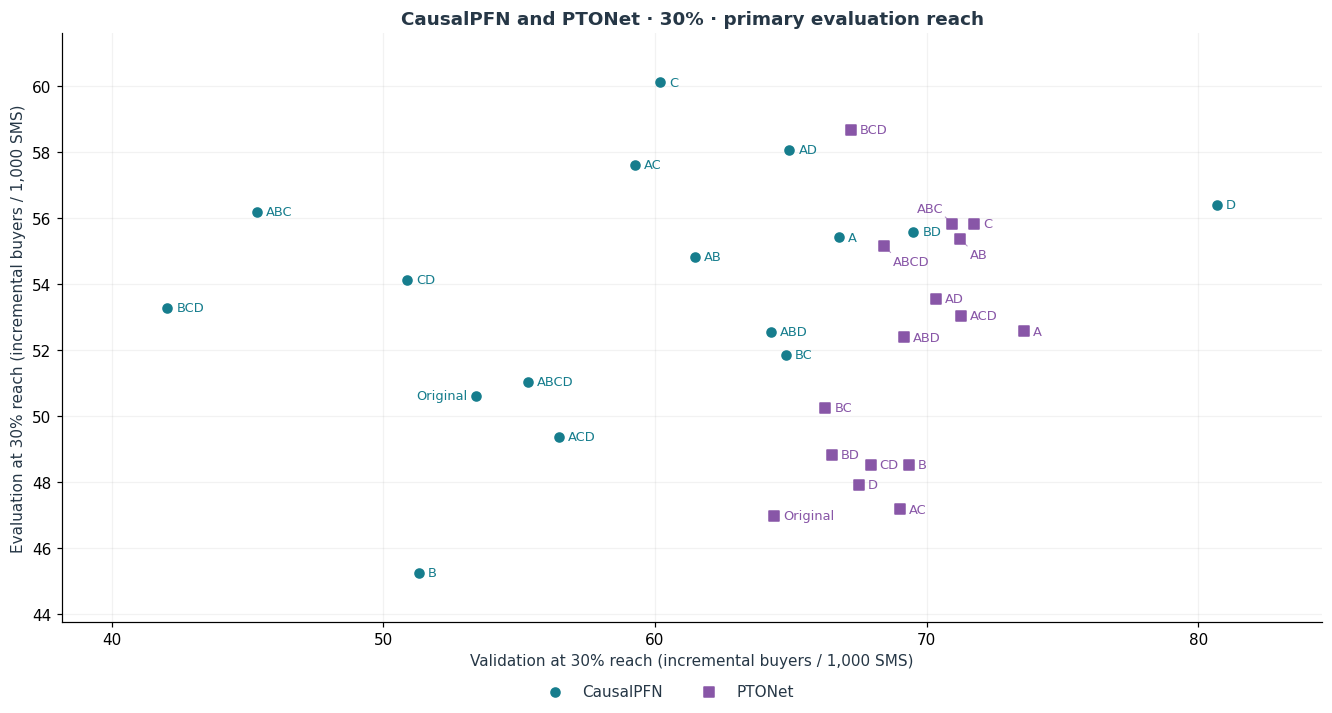

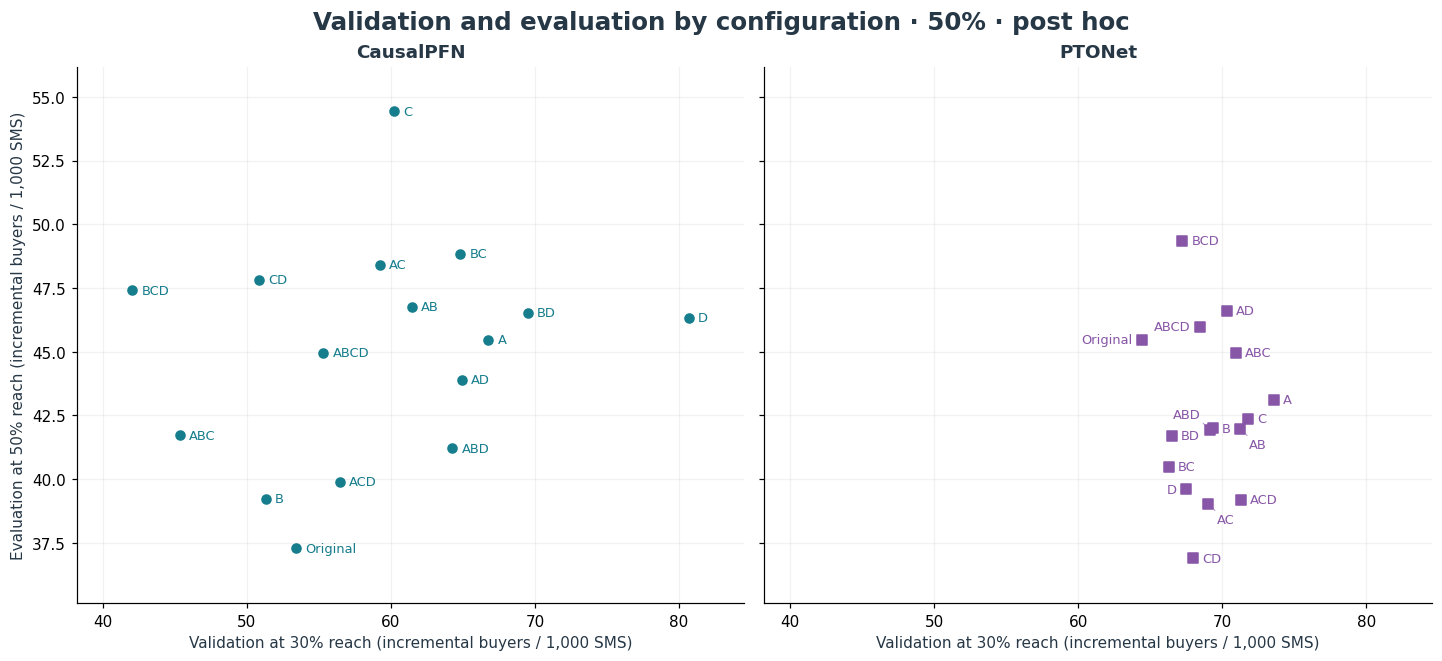

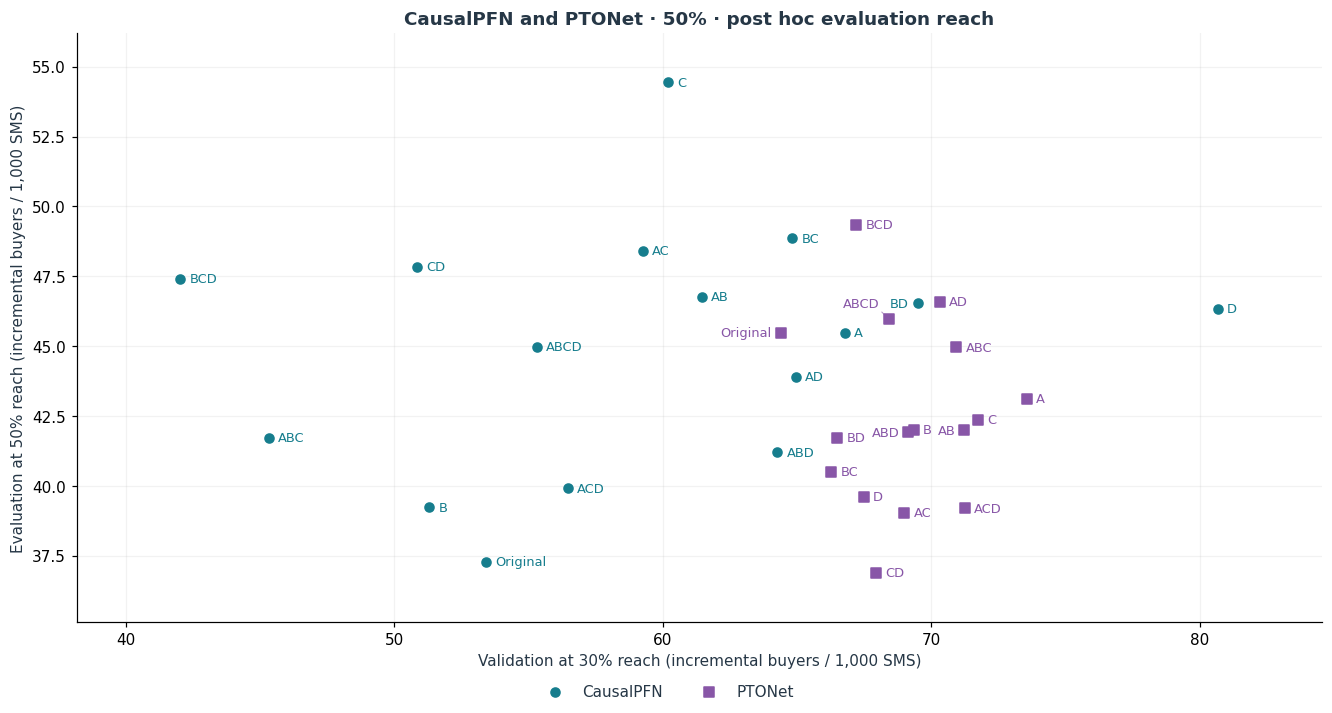

In [12]:
scatter_by_reach = {}
for reach in sorted(REACHES):
    pair = scatter_pair(reach)
    scatter_by_reach[reach] = pair
    for fig in pair:
        display(fig)
        plt.close(fig)

# Keep the selected reach available under the existing review-pack filenames.
figures["validation_vs_evaluation"], figures["validation_vs_evaluation_overlay"] = scatter_by_reach[REACH]

## 9 · Build costs and incremental scoring costs

Shared feature construction is charged once. The ledger includes probes and retries; host fitting costs repeated
at different reaches in the decision table are counted only once here. PTONet ran on CPU.
Serving timings exclude first load and upstream preparation, and include only the measured scope shown in the table.
Host serving measurements are for Original, so these timings do not estimate end-to-end latency for every configuration.

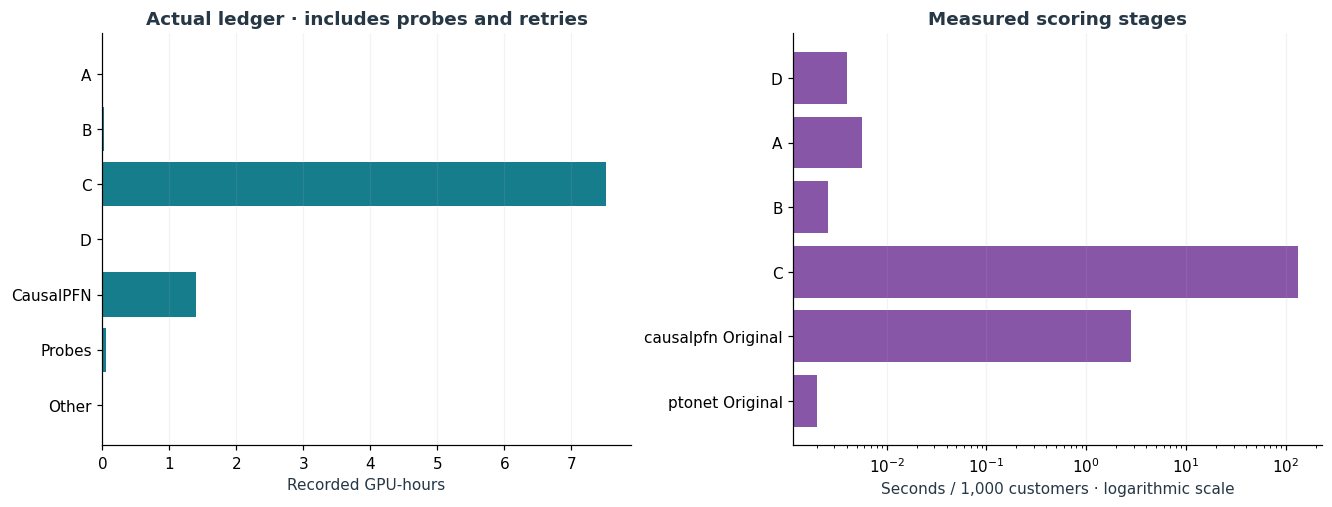

stage,charged_gpu_hours,serving_seconds_per_1000,serving_device,serving_scope
D,0.0000,0.0041,CPU,formulas including six-significant-digit input rounding
A,0.0104,0.0057,GPU,embedding forward pass with prepared basket tensors
B,0.0189,0.0026,CPU,DR regressor with prepared six-field inputs
C,7.5119,132.2946,GPU,two-scenario forward passes with tokenized prompts
causalpfn Original,—,2.8119,GPU,original host prediction per seed
ptonet Original,—,0.0020,CPU,original host prediction per seed


host,config,gpu_hours,sum_wall_seconds,peak_gpu_reserved_gib,peak_rss_gib
causalpfn,Original,0.054,194.921,0.254,3.584
causalpfn,A,0.086,311.252,0.211,3.955
causalpfn,B,0.050,181.520,0.275,3.955
causalpfn,C,0.055,198.638,0.234,3.586
causalpfn,D,0.051,184.398,0.275,3.955
causalpfn,AB,0.084,301.656,0.211,3.960
causalpfn,AC,0.087,313.284,0.209,3.957
causalpfn,AD,0.085,307.650,0.211,3.966
causalpfn,BC,0.053,190.529,0.229,3.957
causalpfn,BD,0.052,187.320,0.256,3.966


In [13]:
stages = compute_stages(bundle)
components = pd.DataFrame(bundle.compute["components"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
axes[0].barh(stages["stage"], stages["gpu_hours"], color="#167d8d")
axes[0].set(xlabel="Recorded GPU-hours", title="Actual ledger · includes probes and retries")
axes[0].invert_yaxis()
axes[0].grid(axis="x", alpha=.15)
axes[1].barh(components["stage"], components["serving_seconds_per_1000"], color="#8856a7")
axes[1].set_xscale("log")
axes[1].set(xlabel="Seconds / 1,000 customers · logarithmic scale", title="Measured scoring stages")
axes[1].invert_yaxis()
axes[1].grid(axis="x", alpha=.15)
keep_figure("compute_and_serving", fig)
cost_columns = ["stage", "charged_gpu_hours", "serving_seconds_per_1000", "serving_device", "serving_scope"]
show_table(components[cost_columns],
           {"charged_gpu_hours": "{:.4f}", "serving_seconds_per_1000": "{:.4f}"})
host_costs = visible_decisions.drop_duplicates(["host", "config"])[
    ["host", "config", "gpu_hours", "sum_wall_seconds", "peak_gpu_reserved_gib", "peak_rss_gib"]
]
show_table(host_costs, {c: "{:.3f}" for c in host_costs.columns[2:]})

## 10 · Interactive comparison explorer

Select the budget and whether to include formula controls. This explorer changes only this panel;
the main analysis uses the editable `REACH` setting above. A static gain plot remains available when widgets are unavailable.

In [14]:
try:
    import ipywidgets as widgets
except ImportError:
    print("Install ipywidgets for the explorer, or edit REACH and rerun the analysis cells.")
else:
    reach_picker = widgets.Dropdown(
        options=[(reach_label(r), r) for r in REACHES], value=REACH, description="Reach:"
    )
    control_picker = widgets.Checkbox(value=INCLUDE_CONTROLS, description="Formula controls")

    def explore(reach, include_controls):
        plot_gains(reach, include_controls)
        plt.show()
        subset = at_reach(table.loc[table["config"].isin(config_names(include_controls))], reach)
        show_table(subset[["host", "config", "challenger_value", "gain", "low_95", "high_95"]],
                   {c: "{:.2f}" for c in ["challenger_value", "gain", "low_95", "high_95"]})

    explorer_output = widgets.interactive_output(
        explore, {"reach": reach_picker, "include_controls": control_picker}
    )
    display(widgets.HBox([reach_picker, control_picker]), explorer_output)

Output()

## 11 · Export a review pack

Set `EXPORT = True` to save the displayed static figures as PNGs and the current tables as CSVs.
Exports go into a separate `notebook-exports` folder. Existing files with the same names are refreshed.
The `scatter-by-reach` subfolder keeps both scatter views for every measured reach.
For a shareable HTML snapshot, see the command in [notebooks/README.md](README.md).

In [15]:
EXPORT = False
if EXPORT:
    destination = PROJECT_ROOT / "reports/retailhero_abcd/notebook-exports"
    destination.mkdir(exist_ok=True)
    for name, fig in figures.items():
        fig.savefig(destination / f"{name}.png", bbox_inches="tight", facecolor="white")
    scatter_dir = destination / "scatter-by-reach"
    scatter_dir.mkdir(exist_ok=True)
    for reach, pair in scatter_by_reach.items():
        for view, fig in zip(("panels", "overlay"), pair, strict=True):
            fig.savefig(scatter_dir / f"{100*reach:.0f}pct_{view}.png",
                        bbox_inches="tight", facecolor="white")
    selected_scores.to_csv(destination / f"configuration_scores_{REACH:.0%}.csv", index=False)
    registered.to_csv(destination / "registered_30pct.csv", index=False)
    ablation.to_csv(destination / f"ablations_{REACH:.0%}.csv", index=False)
    effects.to_csv(destination / f"factorial_effects_{REACH:.0%}.csv", index=False)
    curve_metrics.to_csv(destination / "curve_metrics.csv", index=False)
    print(f"Saved the review pack to {destination} and "
          f"{2*len(scatter_by_reach)} scatter PNGs to {scatter_dir}.")
else:
    print("Exports off. Set EXPORT = True to save the review pack.")

Exports off. Set EXPORT = True to save the review pack.


## Direct Qwen targeting versus Original and ABCD

Frozen Qwen3 8B reads one pre-SMS profile and predicts how sending an SMS changes the customer's purchase probability. Standalone C uses a LoRA-trained Qwen3 8B and ranks customers by the difference between its SMS and no-SMS purchase forecasts.

Each column shows estimated incremental buyers per 1,000 SMS on the same 40,008 evaluation customers. Higher is better. The primary budget targets the top 30%. Random targeting uses the average SMS effect across the entire evaluation cohort. [Prompt, evaluation protocol and paired confidence intervals](../reports/retailhero_abcd/DIRECT_LLM.md).

In [16]:
direct_scores = pd.read_csv(PROJECT_ROOT / "reports/retailhero_abcd/direct-llm-scores.csv")
policy_names = {
    "direct_qwen": "Frozen Qwen3 8B (direct uplift)",
    "ptonet_Original": "PTONet Original",
    "ptonet_ABCD": "PTONet ABCD",
    "causalpfn_Original": "CausalPFN Original",
    "causalpfn_ABCD": "CausalPFN ABCD",
    "standalone_C": "Standalone C (Qwen3 8B LoRA)",
    "random_targeting": "Random targeting",
}
budget_names = {0.10: "10%", 0.20: "20%", 0.30: "30% (primary)", 0.50: "50%"}
full_scores = direct_scores.loc[direct_scores["cohort"].eq("full")]
if len(full_scores) != len(policy_names) * len(budget_names) or not full_scores["customers"].eq(40_008).all():
    raise ValueError("Expected seven policies at four budgets on the same 40,008 customers.")
direct_table = full_scores.pivot(index="policy", columns="reach", values="value")
direct_table = direct_table.reindex(index=policy_names, columns=budget_names)
if not np.isfinite(direct_table.to_numpy()).all():
    raise ValueError("A policy or budget is missing a finite estimate.")
direct_table = direct_table.rename(index=policy_names, columns=budget_names).rename_axis(
    index="Targeting policy", columns="SMS budget"
)
with pd.option_context("display.float_format", "{:.2f}".format):
    display(direct_table)

SMS budget,10%,20%,30% (primary),50%
Targeting policy,,,,
Frozen Qwen3 8B (direct uplift),48.72,36.39,37.61,35.34
PTONet Original,69.99,50.00,46.96,45.47
PTONet ABCD,81.92,69.13,55.16,45.97
CausalPFN Original,47.01,45.74,50.61,37.28
CausalPFN ABCD,85.41,55.05,51.02,44.96
Standalone C (Qwen3 8B LoRA),50.52,37.86,34.14,36.74
Random targeting,33.24,33.24,33.24,33.24


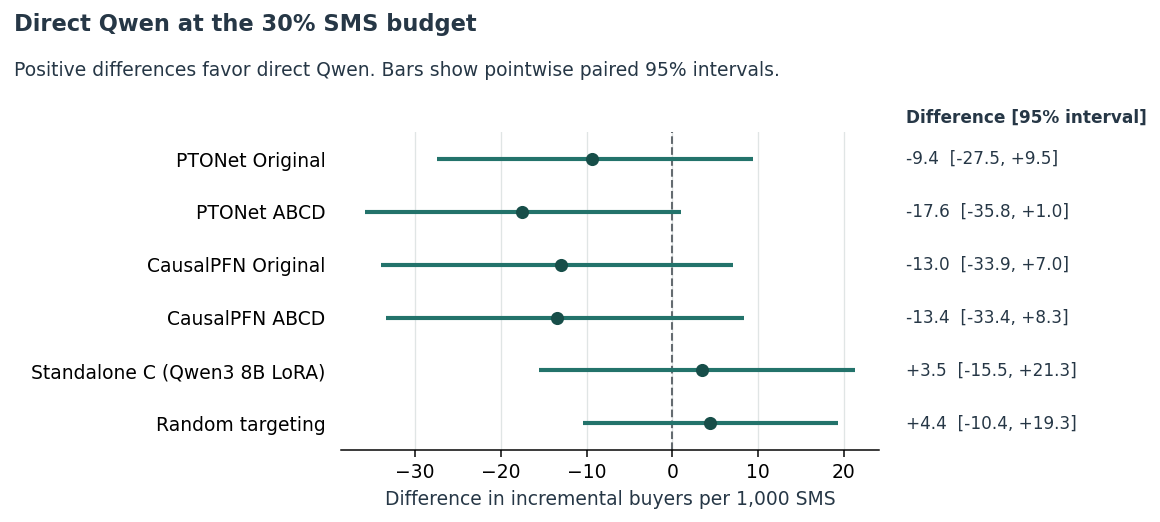

In [17]:
paired = pd.read_csv(PROJECT_ROOT / "reports/retailhero_abcd/direct-llm-contrasts.csv")
primary = paired.loc[
    paired["cohort"].eq("full") & paired["reach"].eq(0.30) & paired["challenger"].eq("direct_qwen")
].set_index("reference", verify_integrity=True)
references = [key for key in policy_names if key != "direct_qwen"]
if set(primary.index) != set(references):
    raise ValueError("Expected all six comparison policies at 30% reach.")
primary = primary.loc[references]
finite = np.isfinite(primary[["gain", "low_95", "high_95"]]).all().all()
if not finite or (primary.low_95 > primary.high_95).any():
    raise ValueError("The paired estimates and ordered interval endpoints must be finite.")
at_30 = full_scores.loc[full_scores["reach"].eq(0.30)].set_index("policy")["value"]
if not np.allclose(primary["gain"], at_30["direct_qwen"] - at_30.loc[references]):
    raise ValueError("The paired gains do not match the direct-minus-comparator scores.")

fig, ax = plt.subplots(figsize=(9.5, 4.2), dpi=135)
fig.subplots_adjust(left=0.28, right=0.70, top=0.76, bottom=0.20)
fig.suptitle("Direct Qwen at the 30% SMS budget", x=0.025, y=0.97, ha="left", weight="bold")
fig.text(0.025, 0.86, "Positive differences favor direct Qwen. Bars show pointwise paired 95% intervals.")
ax.axvline(0, color="#646b70", lw=1.1, ls="--")
y = np.arange(len(primary))
ax.hlines(y, primary.low_95, primary.high_95, color="#23736b", lw=2.2)
ax.scatter(primary.gain, y, color="#174e49", s=36, zorder=3)
ax.set_yticks(y, labels=[policy_names[key] for key in references])
ax.set_ylim(len(y) - 0.5, -0.5)
ax.tick_params(axis="y", length=0, pad=8)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", color="#e0e5e5", lw=0.7)
ax.set_axisbelow(True)
ax.set_xlabel("Difference in incremental buyers per 1,000 SMS")
ax.text(1.05, 1.03, "Difference [95% interval]", transform=ax.transAxes, weight="bold", fontsize=9)
for pos, row in enumerate(primary.itertuples()):
    label = f"{row.gain:+.1f}  [{row.low_95:+.1f}, {row.high_95:+.1f}]"
    ax.text(1.05, pos, label, transform=ax.get_yaxis_transform(), va="center", fontsize=9)
plt.show()

## Source and interpretation notes

- Configuration order and feature widths: `experiments/retailhero_abcd/design.json`.
- Scores, validation values, paired gains, and host costs: `reports/retailhero_abcd/decision-table.csv`.
- Registered/ablation/control contrasts: `comparisons.csv`; marginal block effects: `factorial-effects.csv`.
- Training-seed policies, selected arm counts and full-curve metrics: `seed-policies.csv`.
- Roster, selection, bootstrap settings and lock hashes: `results.json`; measured costs: `compute.json`.
- No customer-level outcomes or prediction archives are required. Statistical estimates are read from the published summaries.
- Adding more plots does not add independent evidence. A new randomized campaign would provide independent confirmation.